In [2]:
import numpy as np
from itertools import *
from math import *
import scipy.special as sc

# Моделирование геометрической вероятности

## Смоделируйте вычисление геометрической вероятности (на примере из лекции про метание дротиков в игровой круг, площадь которого в два раза меньше площади стены). Показать теоретический расчет и графическую иллюстрацию для рассматриваемого примера.

На участке стены расположилась муха, которая в 200 раз меньше этого участка. Ковбой Джон стреляет из пулемёта наугад в этот участок стены. Найти вероятность попадания в муху

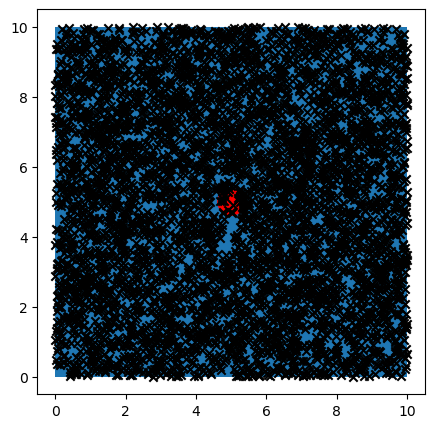

В красный круг из 5000 дротиков попало 30. Доля попавших составила 0.006
0.005


In [3]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle
import numpy as np

def darts(size):
    R = 10
    side = R
    r = side / np.sqrt(200 * np.pi)
    x0, y0 = side / 2, side / 2      

    fig, ax = plt.subplots(figsize=(5, 5))
    ax.add_patch(Rectangle((0, 0), side, side))
    ax.add_patch(Circle((x0, y0), r, facecolor='r'))

    X = np.random.uniform(0, side, size)
    Y = np.random.uniform(0, side, size)
    plt.scatter(X, Y, marker='x', c='black')

    inside = len([d for d in (X - x0) ** 2 + (Y - y0) ** 2 if d <= r ** 2])
    prob = inside / size

    plt.show()
    print(f'В красный круг из {size} дротиков попало {inside}. Доля попавших составила {prob}')

darts(5000)
print(1/200)

# Тема 4

Решить классически и смоделировать решение задачи. В одной урне 15 белых и 5 черных шаров, а в другой - 6 белых и 1 черный шар. Из первой урны случайным образом вынимают 3 шара и опускают во вторую урну. После этого из второй урны также случайно вынимают 1 шар. Найти вероятность того, что шар, вынутый из второй урны - белый.

In [4]:
import random

def trial():
    urn1 = ['W'] * 15 + ['B'] * 5
    urn2 = ['W'] * 6 + ['B'] * 1
    for _ in range(3):
        idx = random.randint(0, len(urn1) - 1)
        ball = urn1.pop(idx)
        urn2.append(ball)
    idx = random.randint(0, len(urn2) - 1)
    ball = urn2.pop(idx)

    return 1 if ball == 'W' else 0


N = 1000000
white_count = 0

for i in range(N):
    white_count += trial()

prob = white_count / N

print(f'Экспериментальная вероятность: {prob:.4f}')
print(f'Теоретическая вероятность:     {1/(sc.comb(20,3)*10)*(10*6+150*7+525*8+455*9):.4f}')

Экспериментальная вероятность: 0.8245
Теоретическая вероятность:     0.8250
